# Final results

Run the baselines and experiments notebooks first; this notebook reads their saved results.

In [1]:
%load_ext autoreload
%autoreload 2

import sys, json, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib

# ---- project paths (works when run from notebooks/ or from the repo root) ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = ROOT / "data" / "processed" / "df_train_20261028.csv"
TEST_PATH  = ROOT / "data" / "processed" / "df_test_20261028.csv"
RESULTS = ROOT / "results"
FINAL = RESULTS / "final"; FINAL.mkdir(parents=True, exist_ok=True)
ARTIFACTS = ROOT / "artifacts"; ARTIFACTS.mkdir(exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
needed = ["src/__init__.py", "src/models/__init__.py", "src/models/data.py", "src/models/train.py",
          "src/models/tune.py", "results/model_comparison.csv", "results/experiments_ablation_fold_scores.csv"]
missing = [f for f in needed if not (ROOT / f).exists()]
assert not missing, f"Missing in {ROOT}: {missing} (run the baselines and experiments notebooks first)"
for p in (TRAIN_PATH, TEST_PATH):
    assert p.exists(), f"Data file not found: {p}"
warnings.filterwarnings("ignore", category=UserWarning)

from src.models.data import (load_xy, FEATURES, SLEEP_FEATURES, ACTIVITY_FEATURES,
                             PERSON_FEATURES, CONTEXT_FEATURES)
from src.models import train as T
from src.models import tune as TU
assert "accuracy" in T.score_predictions(np.array([0, 1]), np.array([.2, .8])), \
    "Old src/models/train.py is loaded: replace it and restart the kernel."
pd.set_option("display.width", 160)

# ---- plot style: thin marks, recessive axes, one accent color ----
FINAL_C, BASE_C, MUTED, INK, INK2 = "#2a78d6", "#a3a29c", "#d9d8d3", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": .8,
    "axes.axisbelow": True, "text.color": INK, "legend.frameon": False,
})
print("ROOT:", ROOT)

ROOT: /home/claude/lifesnaps_modeling


## 1. Locked decisions
Fixed **before** looking at the test set, based on participant-grouped cross-validation of the training file only.

In [2]:
DECISIONS = {
    "final_model": "LightGBM (tuned with grouped CV on all training participants)",
    "features": "all: sleep (main), previous-day activity (main), hour of report, age group, gender, BMI (covariates)",
    "primary_kpi": "accuracy, always reported next to the no-information rate (always predicting 'not bad')",
    "also_reported": "hit rate, false-alarm rate, ROC-AUC, PR-AUC, balanced accuracy",
    "threshold": 0.5,     # team has not decided whether false alarms or misses cost more
    "comparators": ["Always 'not bad' (dummy)", "Logistic (L2)"],
    "n_iter_final_tuning": 20,
    "bootstrap": "1,000 resamples of test participants (not reports), 95% percentile CI",
}
THRESHOLD, N_ITER, N_BOOT, SEED = DECISIONS["threshold"], DECISIONS["n_iter_final_tuning"], 1000, T.SEED
pd.Series(DECISIONS, name="decision").to_frame()

,decision
final_model,LightGBM (tuned with grouped CV on all trainin...
features,"all: sleep (main), previous-day activity (main..."
primary_kpi,"accuracy, always reported next to the no-infor..."
also_reported,"hit rate, false-alarm rate, ROC-AUC, PR-AUC, b..."
threshold,0.5
comparators,"[Always 'not bad' (dummy), Logistic (L2)]"
n_iter_final_tuning,20
bootstrap,"1,000 resamples of test participants (not repo..."


## 2. Data

In [3]:
X_tr, y_tr, g_tr, tab_tr = load_xy(TRAIN_PATH)
X_te, y_te, g_te, tab_te = load_xy(TEST_PATH)

assert list(X_tr.columns) == list(X_te.columns) == FEATURES
assert set(g_tr).isdisjoint(g_te), "A participant appears in both train and test"

data_summary = pd.DataFrame({
    "participants (with mood reports)": [g_tr.nunique(), g_te.nunique()],
    "mood reports": [len(y_tr), len(y_te)],
    "bad-mood rate": [y_tr.mean(), y_te.mean()],
    "accuracy of always 'not bad'": [1 - y_tr.mean(), 1 - y_te.mean()],
}, index=["train", "test"]).round(3)
data_summary.to_csv(FINAL / "data_summary.csv")
data_summary

,participants (with mood reports),mood reports,bad-mood rate,accuracy of always 'not bad'
train,49,3937,0.366,0.634
test,14,1092,0.418,0.582


## 3. Cross-validation evidence (training participants only)
Five participant-grouped folds, identical for every model. Read from the saved results of the baselines and experiments notebooks.

In [4]:
comp = pd.read_csv(RESULTS / "model_comparison.csv")
main = comp[~comp.model.str.contains(r"\|")].copy()          # drop ablation / iteration-2 rows
main["model"] = main.model.replace({"Dummy (most frequent)": "Always 'not bad' (dummy)"})
cv_cols = ["accuracy_mean", "no_info_acc_mean", "hit_rate_mean", "false_alarm_mean",
           "roc_auc_mean", "roc_auc_std", "pr_auc_mean", "balanced_acc_mean"]
cv_table = main.set_index("model")[cv_cols].round(3)
cv_table.to_csv(FINAL / "cv_summary.csv")
cv_table

,accuracy_mean,no_info_acc_mean,hit_rate_mean,false_alarm_mean,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_acc_mean
model,,,,,,,,
Always 'not bad' (dummy),0.635,0.635,0.000,0.000,0.500,0.000,0.365,0.500
Dummy (stratified),0.542,0.635,0.362,0.354,0.504,0.024,0.367,0.504
Logistic (L2),0.474,0.635,0.552,0.568,0.487,0.057,0.367,0.492
Decision tree (d=3),0.459,0.635,0.445,0.526,0.473,0.045,0.361,0.460
Elastic-net LR,0.426,0.635,0.639,0.689,0.469,0.071,0.351,0.475
Random forest,0.469,0.635,0.563,0.582,0.493,0.063,0.378,0.490
LightGBM,0.507,0.635,0.564,0.526,0.529,0.054,0.397,0.519


**Figure 1 — hit rate vs. false-alarm rate (CV).** Each dot is a model at the 0.5 threshold. On the dashed diagonal, a model flags bad and non-bad reports equally often, i.e. it does not discriminate. Distance above the diagonal is real skill.

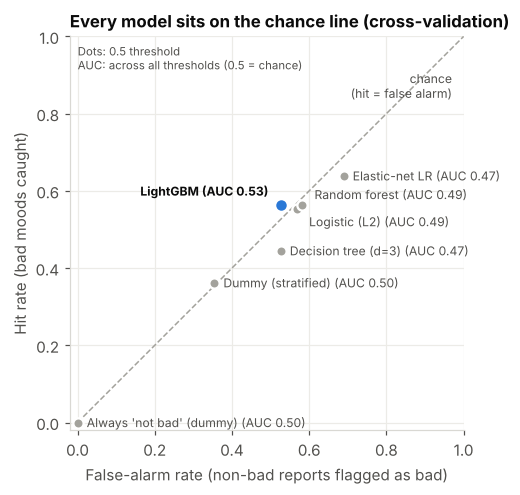

In [5]:
# label offsets (points) for models whose dots sit close together
LABEL_POS = {"LightGBM": (-8, 6, "right"), "Random forest": (8, 4, "left"), "Logistic (L2)": (8, -11, "left")}

def hit_fa_plot(df, x, y, title, path, highlight="LightGBM", auc=None):
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.plot([0, 1], [0, 1], ls="--", c=BASE_C, lw=1)
    ax.text(.97, .91, "chance\n(hit = false alarm)", ha="right", va="top", color=INK2, fontsize=8)
    for name, r in df.iterrows():
        hi = name.startswith(highlight)
        ax.scatter(r[x], r[y], s=70 if hi else 45, color=FINAL_C if hi else BASE_C,
                   edgecolor="white", linewidth=1.5, zorder=3)
        dx, dy, ha = LABEL_POS.get(name, (6, -3, "left"))
        label = f"{name} (AUC {r[auc]:.2f})" if auc else name
        ax.annotate(label, (r[x], r[y]), xytext=(dx, dy), textcoords="offset points", ha=ha,
                    fontsize=8, color=INK if hi else INK2, fontweight="bold" if hi else "normal")
    ax.text(.02, .98, "Dots: 0.5 threshold\nAUC: across all thresholds (0.5 = chance)", ha="left", va="top", fontsize=7.5, color=INK2, transform=ax.transAxes)
    ax.set(xlim=(-.02, 1), ylim=(-.02, 1), xlabel="False-alarm rate (non-bad reports flagged as bad)",
           ylabel="Hit rate (bad moods caught)", title=title)
    ax.set_aspect("equal"); plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()

hit_fa_plot(cv_table, "false_alarm_mean", "hit_rate_mean",
            "Every model sits on the chance line (cross-validation)", FINAL / "fig1_cv_hit_vs_false_alarm.png",
            auc="roc_auc_mean")

**Figure 2 — where the little signal comes from (CV ablation, LightGBM, default settings).** Same folds, three feature sets.

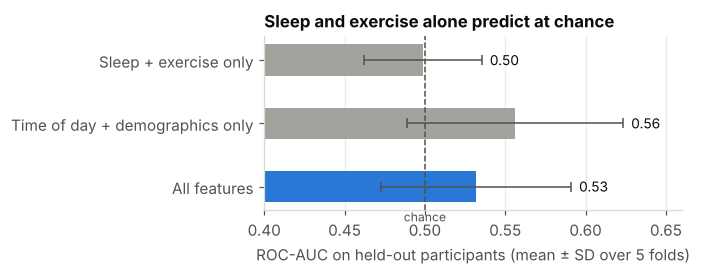

accuracy        hit_rate        false_alarm        roc_auc       
                                    mean    std     mean    std        mean    std    mean    std
feature set                                                                                      
Time of day + demographics only    0.540  0.077    0.555  0.137       0.469  0.176   0.556  0.067
Sleep + exercise only              0.497  0.032    0.510  0.129       0.509  0.113   0.499  0.037
All features                       0.522  0.044    0.532  0.086       0.484  0.081   0.532  0.059

In [6]:
abl = pd.read_csv(RESULTS / "experiments_ablation_fold_scores.csv")
abl = abl[abl.model.str.startswith("LightGBM")].copy()
abl["feature set"] = abl.model.str.split(r" \| ").str[1].map({
    "sleep + activity only": "Sleep + exercise only",
    "context + person only": "Time of day + demographics only",
    "all features": "All features"})
abl_sum = abl.groupby("feature set", sort=False)[["accuracy", "hit_rate", "false_alarm", "roc_auc"]].agg(["mean", "std"]).round(3)
abl_sum.to_csv(FINAL / "cv_ablation.csv")

order = ["Sleep + exercise only", "Time of day + demographics only", "All features"]
m = abl.groupby("feature set")["roc_auc"].agg(["mean", "std"]).loc[order]
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.barh(range(3), m["mean"] - .4, left=.4, height=.5, color=[BASE_C, BASE_C, FINAL_C])
ax.errorbar(m["mean"], range(3), xerr=m["std"], fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
for i, v in enumerate(m["mean"]):
    ax.text(v + m["std"].iloc[i] + .005, i, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.axvline(.5, ls="--", c=INK2, lw=1); ax.text(.5, 2.55, "chance", ha="center", fontsize=8, color=INK2)
ax.set_yticks(range(3), order); ax.invert_yaxis(); ax.set_xlim(.4, .66); ax.grid(axis="y", visible=False)
ax.set(xlabel="ROC-AUC on held-out participants (mean ± SD over 5 folds)",
       title="Sleep and exercise alone predict at chance")
plt.tight_layout(); plt.savefig(FINAL / "fig2_cv_ablation.png", bbox_inches="tight"); plt.show()
abl_sum

## 4. Final model: refit on all training participants
Hyperparameters are re-tuned with grouped CV on the 49 training participants only, then the model is refit on all of them and saved.

In [7]:
search = TU.tune_final(T.make_lightgbm(), TU.SEARCH_SPACES["lightgbm"], X_tr, y_tr, g_tr, n_iter=N_ITER)
final_model = search.best_estimator_
best_params = {k.replace("model__", ""): (float(v) if isinstance(v, (np.floating, float)) else int(v))
               for k, v in search.best_params_.items()}
print(f"Inner grouped-CV ROC-AUC of chosen settings: {search.best_score_:.3f}")

comparators = {
    "Always 'not bad' (dummy)": T.make_dummy("most_frequent").fit(X_tr, y_tr),
    "Logistic (L2)": T.make_logistic(C=1.0).fit(X_tr, y_tr),
}
models = {**comparators, "LightGBM (final)": final_model}

# ---- save the final model + what is needed to reload it ----
import sklearn, lightgbm
joblib.dump(final_model, ARTIFACTS / "lightgbm_final.joblib")
(ARTIFACTS / "lightgbm_final_meta.json").write_text(json.dumps({
    "features": FEATURES, "threshold": THRESHOLD, "best_params": best_params,
    "inner_cv_roc_auc": round(float(search.best_score_), 4), "train_participants": int(g_tr.nunique()),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__},
}, indent=2))
pd.Series(best_params, name="final LightGBM settings").to_frame()

Inner grouped-CV ROC-AUC of chosen settings: 0.534


,final LightGBM settings
colsample_bytree,0.548836
learning_rate,0.048332
min_child_samples,130.000000
n_estimators,363.000000
num_leaves,18.000000
reg_lambda,0.033120


## 5. Test-set evaluation (run once)
15 held-out participants (14 of whom have mood reports) never used in any earlier step. Confidence intervals resample **participants** (not reports), because reports from the same person are not independent.

In [8]:
proba = {name: m.predict_proba(X_te)[:, 1] for name, m in models.items()}
KEY = ["accuracy", "no_info_acc", "hit_rate", "false_alarm", "roc_auc", "pr_auc", "balanced_acc"]
point = pd.DataFrame({n: T.score_predictions(y_te.values, p, THRESHOLD) for n, p in proba.items()}).T[KEY]

# participant-level bootstrap
rng = np.random.default_rng(SEED)
ids = g_te.unique()
rows_of = {i: np.flatnonzero(g_te.values == i) for i in ids}
yv = y_te.values
boot = {n: [] for n in models}
for b in range(N_BOOT):
    idx = np.concatenate([rows_of[i] for i in rng.choice(ids, size=len(ids), replace=True)])
    if len(np.unique(yv[idx])) < 2:
        continue
    for n in models:
        boot[n].append(T.score_predictions(yv[idx], proba[n][idx], THRESHOLD))
boot = {n: pd.DataFrame(v)[KEY] for n, v in boot.items()}
lo = pd.DataFrame({n: b.quantile(.025) for n, b in boot.items()}).T
hi = pd.DataFrame({n: b.quantile(.975) for n, b in boot.items()}).T

fmt = lambda c: point[c].map("{:.3f}".format) + "  [" + lo[c].map("{:.2f}".format) + ", " + hi[c].map("{:.2f}".format) + "]"
test_table = pd.DataFrame({c: fmt(c) for c in KEY})
point.round(4).to_csv(FINAL / "test_metrics_point.csv")
test_table.to_csv(FINAL / "test_metrics_with_ci.csv")
print(f"Test: {g_te.nunique()} participants, {len(y_te)} reports; {len(boot['LightGBM (final)'])} valid bootstrap resamples")
test_table

Test: 14 participants, 1092 reports; 1000 valid bootstrap resamples


,accuracy,no_info_acc,hit_rate,false_alarm,roc_auc,pr_auc,balanced_acc
Always 'not bad' (dummy),"0.582 [0.51, 0.64]","0.582 [0.51, 0.64]","0.000 [0.00, 0.00]","0.000 [0.00, 0.00]","0.500 [0.50, 0.50]","0.418 [0.36, 0.49]","0.500 [0.50, 0.50]"
Logistic (L2),"0.494 [0.41, 0.58]","0.582 [0.51, 0.64]","0.814 [0.65, 0.94]","0.736 [0.51, 0.93]","0.571 [0.52, 0.62]","0.481 [0.40, 0.55]","0.539 [0.49, 0.59]"
LightGBM (final),"0.489 [0.46, 0.53]","0.582 [0.51, 0.64]","0.643 [0.43, 0.79]","0.621 [0.42, 0.78]","0.522 [0.48, 0.56]","0.438 [0.37, 0.55]","0.511 [0.48, 0.53]"


**Pre-specified comparisons** (paired: each bootstrap resample scores both models on the same people).

In [9]:
fm, lr = boot["LightGBM (final)"], boot["Logistic (L2)"]
diffs = pd.DataFrame({
    "LightGBM accuracy − always 'not bad' accuracy": fm["accuracy"] - fm["no_info_acc"],
    "LightGBM hit rate − false-alarm rate": fm["hit_rate"] - fm["false_alarm"],
    "LightGBM ROC-AUC − 0.5 (chance)": fm["roc_auc"] - .5,
    "LightGBM ROC-AUC − Logistic ROC-AUC": fm["roc_auc"] - lr["roc_auc"],
})
pt = pd.Series({
    diffs.columns[0]: point.loc["LightGBM (final)", "accuracy"] - point.loc["LightGBM (final)", "no_info_acc"],
    diffs.columns[1]: point.loc["LightGBM (final)", "hit_rate"] - point.loc["LightGBM (final)", "false_alarm"],
    diffs.columns[2]: point.loc["LightGBM (final)", "roc_auc"] - .5,
    diffs.columns[3]: point.loc["LightGBM (final)", "roc_auc"] - point.loc["Logistic (L2)", "roc_auc"],
})
comparisons = pd.DataFrame({"difference": pt, "95% CI low": diffs.quantile(.025), "95% CI high": diffs.quantile(.975)}).round(3)
comparisons["CI excludes 0"] = (comparisons["95% CI low"] > 0) | (comparisons["95% CI high"] < 0)
comparisons.to_csv(FINAL / "test_comparisons.csv")
comparisons

,difference,95% CI low,95% CI high,CI excludes 0
LightGBM accuracy − always 'not bad' accuracy,-0.093,-0.174,0.002,False
LightGBM hit rate − false-alarm rate,0.021,-0.037,0.068,False
LightGBM ROC-AUC − 0.5 (chance),0.022,-0.020,0.059,False
LightGBM ROC-AUC − Logistic ROC-AUC,-0.049,-0.079,-0.021,True


**Figure 3 — test set: hit rate vs. false-alarm rate, and ROC curves.**

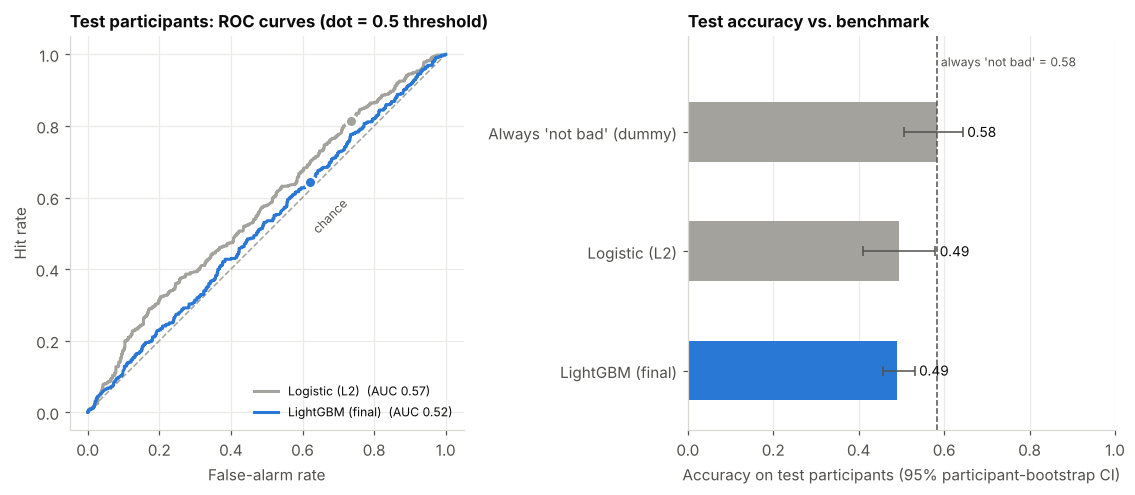

In [10]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
ax = axes[0]
ax.plot([0, 1], [0, 1], ls="--", c=BASE_C, lw=1)
for name, p in proba.items():
    if name.startswith("Always"):
        continue
    fpr, tpr, _ = roc_curve(y_te, p)
    hi_ = name.startswith("LightGBM")
    ax.plot(fpr, tpr, lw=2, color=FINAL_C if hi_ else BASE_C,
            label=f"{name}  (AUC {point.loc[name, 'roc_auc']:.2f})")
    r = point.loc[name]
    ax.scatter(r["false_alarm"], r["hit_rate"], s=55, color=FINAL_C if hi_ else BASE_C,
               edgecolor="white", linewidth=1.5, zorder=3)
ax.text(.62, .5, "chance", ha="left", color=INK2, fontsize=8, rotation=45)
ax.set(xlabel="False-alarm rate", ylabel="Hit rate", title="Test participants: ROC curves (dot = 0.5 threshold)")
ax.legend(loc="lower right", fontsize=8); ax.set_aspect("equal")

# accuracy vs the always-'not bad' benchmark, with participant-bootstrap CIs
ax = axes[1]
names = list(models)
acc, acc_lo, acc_hi = point["accuracy"], lo["accuracy"], hi["accuracy"]
colors = [BASE_C if not n.startswith("LightGBM") else FINAL_C for n in names]
ax.barh(range(len(names)), acc[names], height=.5, color=colors)
ax.errorbar(acc[names], range(len(names)), xerr=[acc[names] - acc_lo[names], acc_hi[names] - acc[names]],
            fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
for i, n in enumerate(names):
    ax.text(acc_hi[n] + .01, i, f"{acc[n]:.2f}", va="center", fontsize=9)
nir = point["no_info_acc"].iloc[0]
ax.axvline(nir, ls="--", c=INK2, lw=1)
ax.text(nir + .01, -.55, f"always 'not bad' = {nir:.2f}", ha="left", fontsize=8, color=INK2)
ax.set_yticks(range(len(names)), names); ax.set_ylim(len(names) - .5, -.8); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set(xlabel="Accuracy on test participants (95% participant-bootstrap CI)", title="Test accuracy vs. benchmark")
plt.tight_layout(); plt.savefig(FINAL / "fig3_test_roc_and_accuracy.png", bbox_inches="tight"); plt.show()

In [11]:
# Confusion matrix for the final model on the test set (counts of mood reports)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_te, (proba["LightGBM (final)"] >= THRESHOLD).astype(int))
cm_df = pd.DataFrame(cm, index=["actual: not bad", "actual: bad"], columns=["predicted: not bad", "predicted: bad"])
cm_df.to_csv(FINAL / "test_confusion_matrix.csv")
cm_df

,predicted: not bad,predicted: bad
actual: not bad,241,395
actual: bad,163,293


## 6. What the final model relies on
SHAP values for the final LightGBM on the training reports, grouped by feature type.

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


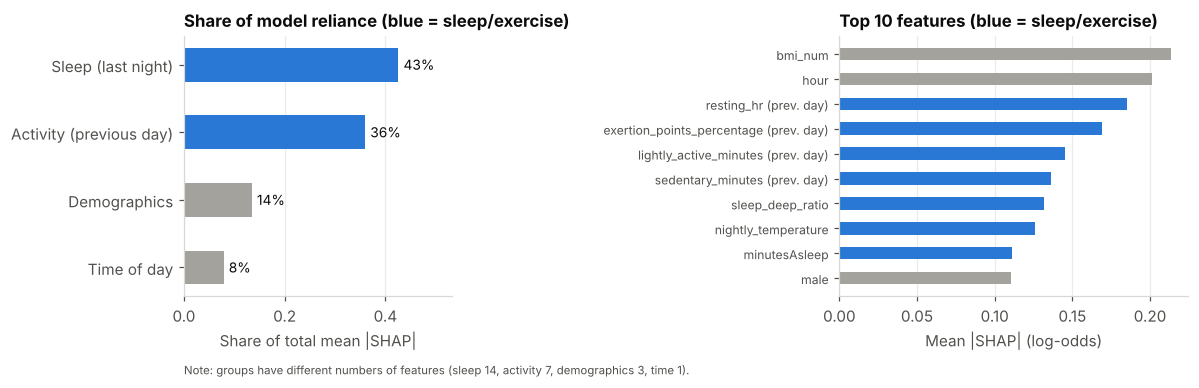

,share
Time of day,0.079
Demographics,0.135
Activity (previous day),0.360
Sleep (last night),0.426


In [12]:
import shap
lgb = final_model.named_steps["model"]
sv = shap.TreeExplainer(lgb)(X_tr)
imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES)
group_of = {**{f: "Sleep (last night)" for f in SLEEP_FEATURES},
            **{f: "Activity (previous day)" for f in ACTIVITY_FEATURES},
            **{f: "Demographics" for f in PERSON_FEATURES},
            **{f: "Time of day" for f in CONTEXT_FEATURES}}
grp = imp.groupby(group_of).sum().sort_values()
share = (grp / grp.sum()).round(3)
imp.sort_values(ascending=False).to_csv(FINAL / "final_mean_abs_shap.csv")
share.to_csv(FINAL / "final_shap_share_by_group.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.barh(range(len(share)), share.values, height=.5, color=[FINAL_C if g.startswith(("Sleep", "Activity")) else BASE_C for g in share.index])
for i, v in enumerate(share.values):
    ax.text(v + .01, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_yticks(range(len(share)), share.index); ax.set_xlim(0, max(share) * 1.25); ax.grid(axis="y", visible=False)
ax.set(xlabel="Share of total mean |SHAP|", title="Share of model reliance (blue = sleep/exercise)")
ax.text(0, -0.30, "Note: groups have different numbers of features (sleep 14, activity 7, demographics 3, time 1).",
        transform=ax.transAxes, fontsize=7.5, color=INK2)
ax = axes[1]
top = imp.sort_values().tail(10)
ax.barh(range(len(top)), top.values, height=.5, color=[FINAL_C if group_of[f].startswith(("Sleep", "Activity")) else BASE_C for f in top.index])
ax.set_yticks(range(len(top)), [f.replace("daily_", "").replace("_lag1", " (prev. day)") for f in top.index], fontsize=8)
ax.grid(axis="y", visible=False); ax.set(xlabel="Mean |SHAP| (log-odds)", title="Top 10 features (blue = sleep/exercise)")
plt.tight_layout(); plt.savefig(FINAL / "fig4_final_shap.png", bbox_inches="tight"); plt.show()
share.rename("share").to_frame()

## 7. Summary for the presentation

In [13]:
f, b = point.loc["LightGBM (final)"], lo.loc["LightGBM (final)"]
h = hi.loc["LightGBM (final)"]
summary = pd.DataFrame([
    ("Training data", f"{g_tr.nunique()} participants, {len(y_tr):,} mood reports ({y_tr.mean():.0%} bad)"),
    ("Test data", f"{g_te.nunique()} unseen participants, {len(y_te):,} mood reports ({y_te.mean():.0%} bad)"),
    ("CV: best model (LightGBM)", f"accuracy {cv_table.loc['LightGBM','accuracy_mean']:.2f} vs. {cv_table.loc['LightGBM','no_info_acc_mean']:.2f} always 'not bad'; "
                                  f"hit {cv_table.loc['LightGBM','hit_rate_mean']:.2f} vs. false alarm {cv_table.loc['LightGBM','false_alarm_mean']:.2f}; "
                                  f"ROC-AUC {cv_table.loc['LightGBM','roc_auc_mean']:.2f}"),
    ("CV: sleep + exercise only", f"ROC-AUC {abl_sum.loc['Sleep + exercise only', ('roc_auc','mean')]:.2f}"),
    ("CV: time of day + demographics only", f"ROC-AUC {abl_sum.loc['Time of day + demographics only', ('roc_auc','mean')]:.2f}"),
    ("TEST accuracy (final)", f"{f['accuracy']:.2f} [{b['accuracy']:.2f}, {h['accuracy']:.2f}] vs. {f['no_info_acc']:.2f} always 'not bad'"),
    ("TEST hit / false-alarm rate", f"{f['hit_rate']:.2f} / {f['false_alarm']:.2f}"),
    ("TEST ROC-AUC", f"{f['roc_auc']:.2f} [{b['roc_auc']:.2f}, {h['roc_auc']:.2f}]"),
    ("Reliance on sleep + exercise (SHAP share)", f"{share.get('Sleep (last night)', 0) + share.get('Activity (previous day)', 0):.0%}"),
], columns=["item", "value"]).set_index("item")
summary.to_csv(FINAL / "presentation_summary.csv")
summary

,value
item,
Training data,"49 participants, 3,937 mood reports (37% bad)"
Test data,"14 unseen participants, 1,092 mood reports (42..."
CV: best model (LightGBM),accuracy 0.51 vs. 0.64 always 'not bad'; hit 0...
CV: sleep + exercise only,ROC-AUC 0.50
CV: time of day + demographics only,ROC-AUC 0.56
TEST accuracy (final),"0.49 [0.46, 0.53] vs. 0.58 always 'not bad'"
TEST hit / false-alarm rate,0.64 / 0.62
TEST ROC-AUC,"0.52 [0.48, 0.56]"
Reliance on sleep + exercise (SHAP share),79%
